# 03 — Model Training

## Objective

Develop and compare XGBoost regression pipelines for predicting house sale prices. The notebook benchmarks a baseline model, tunes its hyperparameters with Optuna, investigates feature importance, and compares three feature-selection strategies. The final model is selected based on **validation performance, computational cost, and pipeline simplicity**.

## Experimental plan

1. **Data preparation:** load the original 79 input features and reserve a 20% holdout set.
2. **Baseline:** create a single `Pipeline` combining `build_preprocessor()` and `XGBRegressor`.
3. **Evaluation protocol:** define RMSLE and use shuffled five-fold cross-validation on the training set.
4. **Hyperparameter tuning:** optimize XGBoost with Optuna and inspect the optimization history.
5. **Model diagnostics:** compare baseline and tuned train/validation results and inspect feature importance.
6. **Feature-selection comparison:** evaluate three workflows using `SelectFromModel`:
   - **A — Optuna → Feature Selection:** tune the full-feature model, then select 87 features without re-tuning.
   - **B — Feature Selection → Optuna:** fix an 87-feature selector and tune the downstream XGBoost.
   - **C — Joint Optimization:** tune the downstream XGBoost and the number of selected features together.
7. **Decision:** compare cross-validation RMSLE and select a practical pipeline for subsequent final evaluation.

## Evaluation rules

- All tuning and selection use only `X_train` / `y_train`; **the holdout (`X_test` / `y_test`) is not evaluated in this notebook**.
- Preprocessing and model-based selection remain **inside each cross-validation fold** to prevent validation information from entering their fitting stages.
- The training objective is squared error on untransformed `SalePrice`. RMSLE is the selection metric; negative price predictions are clipped to zero **for scoring only**.
- Results from a hyperparameter search are useful for model selection, but the minimum cross-validation score may be optimistic because the same folds guided tuning. A separate holdout evaluation is still required.

---

## 1. Environment and imports

Load the project dependencies, preprocessing builder, XGBoost, model-selection tools, and Optuna.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_house_prices

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_log_error, make_scorer, mean_absolute_error, mean_squared_error
from sklearn.feature_selection import SelectFromModel

from xgboost import XGBRegressor

from src.preprocessing import build_preprocessor

import optuna

## 2. Data loading and holdout split

Load the raw training CSV, remove the identifier and target from the predictors, and reserve 20% of observations as a holdout. All subsequent experiments use only the 80% training partition.

In [2]:
RANDOM_STATE = 42985

df = load_house_prices(source="private")

X = df.drop(columns=["Id", "SalePrice"])
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 79)
X_test: (292, 79)
y_train: (1168,)
y_test: (292,)


## 3. Baseline pipeline

Combine trainable preprocessing and XGBoost in a single scikit-learn `Pipeline`. The baseline configuration is a reference point rather than a tuned optimum.

In [3]:
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", build_preprocessor()),
        (
            "model",
            XGBRegressor(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

print(model_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('masonry_area',
                                                  PositiveMedianImputer(),
                                                  ['MasVnrArea']),
                                                 ('masonry_type',
                                                  Pipeline(steps=[('imputer',
                                                                   MasonryTypeImputer()),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MasVnrType', 'MasVnrArea']),
                                                 ('age_features',
                                 

## 4. Metric and cross-validation setup

Define RMSLE, which measures squared errors on the `log1p` scale, and adapt it to scikit-learn’s maximize-score convention.

In [4]:
def rmsle(y_true, y_pred):
    """Calculate Root Mean Squared Logarithmic Error."""

    y_pred = np.maximum(y_pred, 0)

    return np.sqrt(
        mean_squared_log_error(y_true, y_pred)
    )

rmsle_scorer = make_scorer(
    rmsle,
    greater_is_better=False
)

### Five-fold cross-validation

Use shuffled `KFold` with a fixed random state. Each fold fits its own independent copy of the preprocessing-and-model pipeline.

In [5]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

## 5. Baseline cross-validation

Assess both training and validation RMSLE for the baseline pipeline without touching the holdout set.

In [6]:
cv_results = cross_validate(
    estimator=model_pipeline,
    X=X_train,
    y=y_train,
    scoring={"rmsle": rmsle_scorer},
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

train_rmsle = -cv_results["train_rmsle"]
val_rmsle = -cv_results["test_rmsle"]

print(f"Train RMSLE: {train_rmsle.mean():.4f} ± {train_rmsle.std():.4f}")
print(f"Validation RMSLE: {val_rmsle.mean():.4f} ± {val_rmsle.std():.4f}")


Train RMSLE: 0.0489 ± 0.0018
Validation RMSLE: 0.1206 ± 0.0133


### Per-fold results and fit times

Compare the individual fold scores and the train–validation gap. Differences between folds may reflect differing validation-set difficulty.

In [7]:
cv_summary = pd.DataFrame({
    "Fold": range(1, cv.get_n_splits() + 1),
    "Train RMSLE": train_rmsle,
    "Validation RMSLE": val_rmsle,
    "Fit time (s)": cv_results["fit_time"]
})

cv_summary["Overfitting gap"] = (
    cv_summary["Validation RMSLE"] - cv_summary["Train RMSLE"]
)

display(cv_summary.round(4))

,Fold,Train RMSLE,Validation RMSLE,Fit time (s),Overfitting gap
0,1,0.0482,0.1410,0.7488,0.0929
1,2,0.0487,0.1100,0.7747,0.0613
2,3,0.0469,0.1284,0.7577,0.0816
3,4,0.0486,0.1196,0.7454,0.0711
4,5,0.0523,0.1037,0.7423,0.0514


### Baseline generalization plot

Visualize training versus validation RMSLE across the five folds.

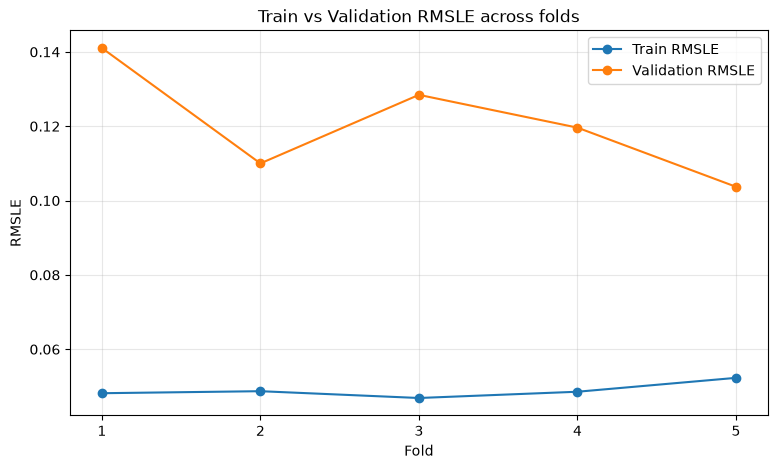

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    cv_summary["Fold"],
    cv_summary["Train RMSLE"],
    marker="o",
    label="Train RMSLE"
)

plt.plot(
    cv_summary["Fold"],
    cv_summary["Validation RMSLE"],
    marker="o",
    label="Validation RMSLE"
)

plt.xlabel("Fold")
plt.ylabel("RMSLE")
plt.title("Train vs Validation RMSLE across folds")
plt.xticks(cv_summary["Fold"])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Hyperparameter optimization with Optuna

Tune XGBoost on the complete, preprocessed feature set. All trials use five-fold CV on `X_train`; `X_test` remains untouched.

### Search-space definition and objective

Each Optuna trial samples eight XGBoost hyperparameters, builds a fresh pipeline, and returns the **mean validation RMSLE** from five-fold CV. The preprocessing is fitted separately within each fold.

In [9]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-4, 10.0, log=True
        )
    }

    trial_pipeline = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", XGBRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        ))
    ])

    results = cross_validate(
        estimator=trial_pipeline,
        X=X_train,
        y=y_train,
        scoring={"rmsle": rmsle_scorer},
        cv=cv,
        n_jobs=-1
    )

    return -results["test_rmsle"].mean()

### Run hyperparameter search

Use 50 TPE trials to identify promising XGBoost hyperparameters on the fixed CV protocol.

In [10]:
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study.optimize(objective, n_trials=50)

print(f"Total trials: {len(study.trials)}")
print(f"Best RMSLE: {study.best_value:.4f}")
print("Best parameters:")

for name, value in study.best_params.items():
    print(f"  {name}: {value}")

[I 2026-11-14 12:48:43,211] A new study created in memory with name: no-name-4874fb4b-166a-41a5-beda-0505015e3326
[I 2026-11-14 12:48:45,770] Trial 0 finished with value: 0.12768335038015638 and parameters: {'n_estimators': 243, 'max_depth': 3, 'learning_rate': 0.1528499136430771, 'min_child_weight': 3, 'subsample': 0.6318641411550002, 'colsample_bytree': 0.8302499881893453, 'reg_alpha': 0.09913374447112994, 'reg_lambda': 0.002025830407277523}. Best is trial 0 with value: 0.12768335038015638.
[I 2026-11-14 12:48:50,406] Trial 1 finished with value: 0.12491338108552888 and parameters: {'n_estimators': 789, 'max_depth': 7, 'learning_rate': 0.09534821704789354, 'min_child_weight': 6, 'subsample': 0.700631854775894, 'colsample_bytree': 0.6718683465820375, 'reg_alpha': 0.011065518206672877, 'reg_lambda': 0.16781967375522766}. Best is trial 1 with value: 0.12491338108552888.
[I 2026-11-14 12:48:53,834] Trial 2 finished with value: 0.13025660597607983 and parameters: {'n_estimators': 141, 'ma

Total trials: 50
Best RMSLE: 0.1174
Best parameters:
  n_estimators: 606
  max_depth: 3
  learning_rate: 0.04898338493290398
  min_child_weight: 4
  subsample: 0.6047050917409649
  colsample_bytree: 0.7164888104969732
  reg_alpha: 1.4687221482811246
  reg_lambda: 0.0036028306853463006


### Extract Optuna trial history

Collect per-trial RMSLE and the best score achieved up to each trial.

In [11]:
trial_numbers = []
trial_values = []

for trial in study.trials:
    if trial.value is not None:
        trial_numbers.append(trial.number)
        trial_values.append(trial.value)

best_so_far = []
current_best = float("inf")

for value in trial_values:
    current_best = min(current_best, value)
    best_so_far.append(current_best)

### Hyperparameter optimization progress

The per-trial curve can fluctuate because every trial uses different hyperparameters. The best-so-far curve can only decrease or stay constant; it indicates progress of the search, not training loss across epochs.

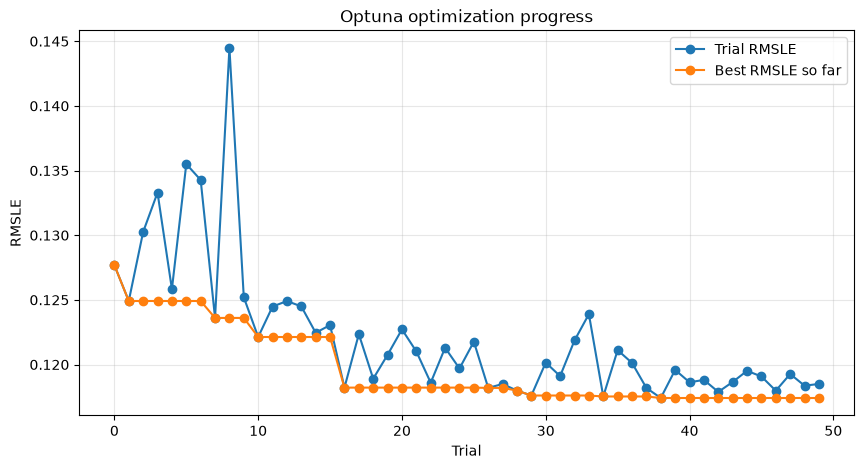

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    trial_numbers,
    trial_values,
    marker="o",
    linestyle="-",
    label="Trial RMSLE",
)

plt.plot(
    trial_numbers,
    best_so_far,
    marker="o",
    linestyle="-",
    label="Best RMSLE so far",
)

plt.xlabel("Trial")
plt.ylabel("RMSLE")
plt.title("Optuna optimization progress")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Baseline vs. tuned XGBoost

Compare performance on the same five folds. The goal is better validation RMSLE, not necessarily the lowest training error.

### Cross-validated model comparison

Re-evaluate the tuned pipeline with the same folds, including training scores. A smaller train–validation gap is a useful diagnostic, but validation RMSLE remains the primary comparison metric.

In [13]:

tuned_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **study.best_params,
    )),
])

tuned_cv_results = cross_validate(
    estimator=tuned_pipeline,
    X=X_train,
    y=y_train,
    scoring={"rmsle": rmsle_scorer},
    cv=cv,
    n_jobs=1,
    return_train_score=True,
)

tuned_train_rmsle = -tuned_cv_results["train_rmsle"]
tuned_val_rmsle = -tuned_cv_results["test_rmsle"]

comparison = pd.DataFrame({
    "Model": ["Baseline", "Tuned"],
    "Train RMSLE": [
        train_rmsle.mean(),
        tuned_train_rmsle.mean(),
    ],
    "Validation RMSLE": [
        val_rmsle.mean(),
        tuned_val_rmsle.mean(),
    ],
})

comparison["Overfitting gap"] = (
    comparison["Validation RMSLE"] - comparison["Train RMSLE"]
)

display(comparison.round(4))


,Model,Train RMSLE,Validation RMSLE,Overfitting gap
0,Baseline,0.0489,0.1206,0.0716
1,Tuned,0.0515,0.1175,0.0660


## 8. Feature importance and feature-selection experiments

Inspect the fitted model’s feature importances, then compare alternative selection-and-tuning workflows using CV. Because the selector is part of the pipeline, feature selection is learned **inside each fold**, avoiding leakage from its validation partition.

### Importance estimation

Fit the tuned pipeline on **X_train only** for exploratory feature-importance analysis. XGBoost importance scores describe this particular fitted model; they are not proof of causality or guaranteed performance contribution.

In [14]:
tuned_pipeline.fit(X_train, y_train)

feature_names = (
    tuned_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    tuned_pipeline.named_steps["model"]
    .feature_importances_
)

feature_importance = pd.Series(
    importances,
    index=feature_names,
).sort_values(ascending=False)

display(feature_importance.head(20))

ExterQual               0.172331
OverallQual             0.143476
GarageCars              0.075226
TotalSF                 0.066864
BsmtQual                0.041397
GarageFinish            0.033957
MSZoning_RM             0.022460
FullBath                0.021799
CentralAir              0.021502
TotalBathrooms          0.020642
SaleType_New            0.018236
KitchenAbvGr            0.016045
GarageType_BuiltIn      0.015231
MSSubClass_60           0.014853
Neighborhood_OldTown    0.014821
FireplaceQu             0.012744
GarageCond              0.011711
KitchenQual             0.011337
GarageQual              0.010633
2ndFlrSF                0.010356
dtype: float32

### Top 20 features

Plot the strongest features as ranked by the fitted XGBoost estimator.

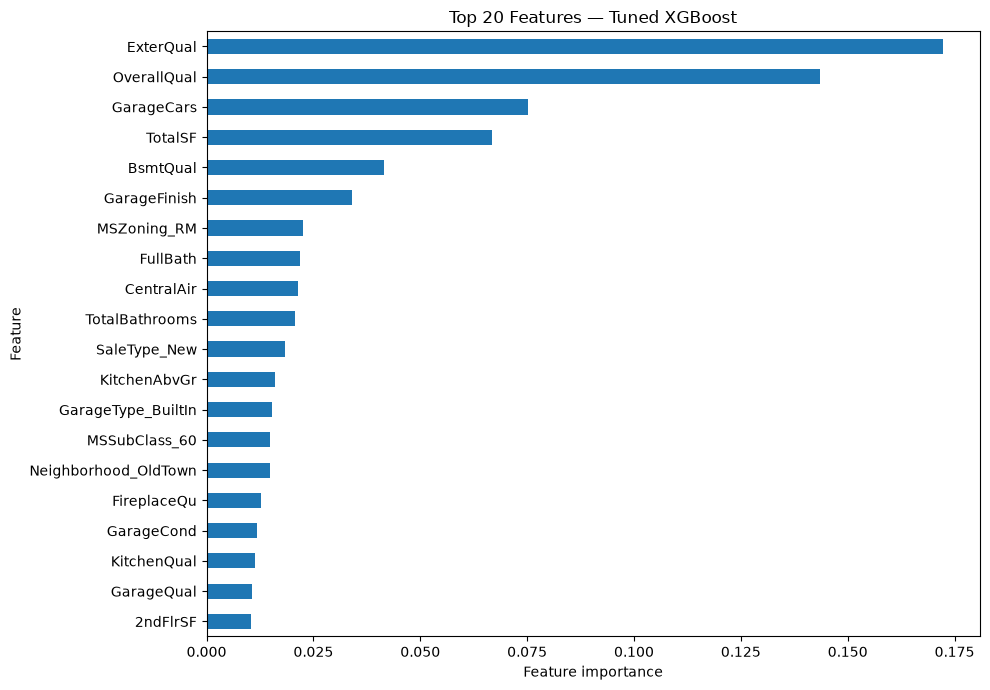

In [15]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 7))

top_features.sort_values().plot.barh()

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top 20 Features — Tuned XGBoost")
plt.tight_layout()
plt.show()

### Importance concentration and unused features

Check how many output features have zero/nonzero importance and how many account for different cumulative-importance levels. These counts describe the fitted model only.

In [16]:
print(f"Total features: {len(feature_importance)}")
print(f"Non-zero importance: {(feature_importance > 0).sum()}")
print(f"Zero importance: {(feature_importance == 0).sum()}")

cumulative_importance = feature_importance.cumsum()

for threshold in [0.80, 0.90, 0.95, 0.99]:
    n_features = (cumulative_importance < threshold).sum() + 1

    print(
        f"Features needed for {threshold:.0%} cumulative importance: "
        f"{n_features}"
    )


Total features: 244
Non-zero importance: 164
Zero importance: 80
Features needed for 80% cumulative importance: 25
Features needed for 90% cumulative importance: 51
Features needed for 95% cumulative importance: 87
Features needed for 99% cumulative importance: 140


### Cumulative feature importance

Visualize the concentration of importance across the ranked features. A 95% cumulative-importance threshold is **not** itself a validated feature-selection criterion.

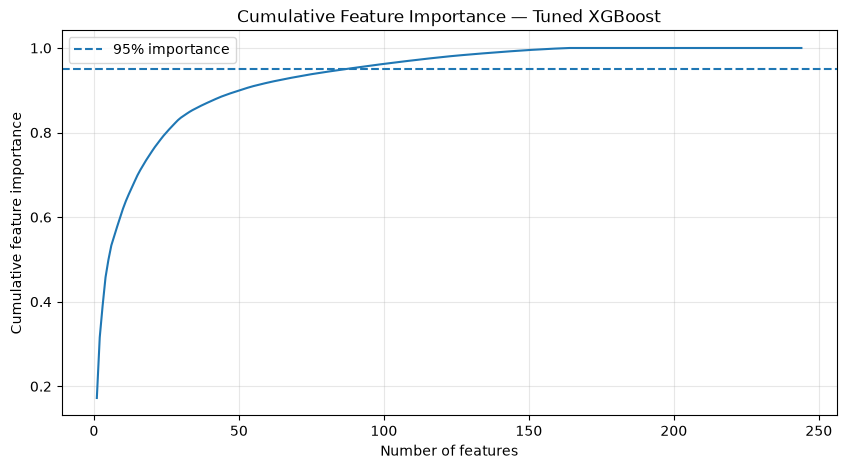

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_importance) + 1),
    cumulative_importance.values,
)

plt.axhline(0.95, linestyle="--", label="95% importance")

plt.xlabel("Number of features")
plt.ylabel("Cumulative feature importance")
plt.title("Cumulative Feature Importance — Tuned XGBoost")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Strategy A — Optuna followed by Feature Selection

The original full-feature Optuna result is retained; the 87-feature selector is added afterward without retuning the downstream model.

#### Selection pipeline

Use the full-feature Optuna hyperparameters in both the auxiliary XGBoost selector and the final model. `threshold=-np.inf` with `max_features=87` keeps the 87 highest-ranked features *within each training fold*, not a single globally fixed list.

In [18]:
selected_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("selector", SelectFromModel(
        estimator=XGBRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **study.best_params,
        ),
        threshold=-np.inf,
        max_features=87,
    )),
    ("model", XGBRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **study.best_params,
    ))
])

### Strategy A — five-fold CV results

Evaluate the selected-feature pipeline using the same five folds as the full-feature model.

In [19]:
selected_cv_results = cross_validate(
    estimator=selected_pipeline,
    X=X_train,
    y=y_train,
    scoring={"rmsle": rmsle_scorer},
    cv=cv,
    n_jobs=1,
    return_train_score=True,
)

selected_train_rmsle = -selected_cv_results["train_rmsle"]
selected_val_rmsle = -selected_cv_results["test_rmsle"]

print(f"Selected Train RMSLE: {selected_train_rmsle.mean():.4f}")
print(f"Selected Validation RMSLE: {selected_val_rmsle.mean():.4f}")
print(f"Tuned Full Validation RMSLE: {tuned_val_rmsle.mean():.4f}")


Selected Train RMSLE: 0.0535
Selected Validation RMSLE: 0.1184
Tuned Full Validation RMSLE: 0.1175


### Strategy A — interim interpretation

Using 87 selected features with the hyperparameters tuned on all features produced **0.1184 validation RMSLE**, compared with **0.1175** for the tuned full-feature model. The smaller train–validation gap did not translate into better validation RMSLE. This is an interim result rather than a final decision: the following sections test whether tuning after selection or tuning the selection size jointly changes the conclusion.

### Strategy B — Feature Selection followed by Optuna

Fix the feature-selection method and its 87-feature limit first, then re-optimize only the final XGBoost for the reduced representation.

#### Optimization objective for Strategy B

Keep the selector configuration and its 87-feature limit fixed; Optuna searches only the hyperparameters of the downstream XGBoost. The selector itself still fits anew inside every CV training fold.

In [20]:
def objective_selected(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-4, 10.0, log=True
        ),
    }

    pipeline = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("selector", SelectFromModel(
            estimator=XGBRegressor(
                random_state=RANDOM_STATE,
                n_jobs=-1,
                **study.best_params,
            ),
            threshold=-np.inf,
            max_features=87,
        )),
        ("model", XGBRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )),
    ])

    results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        scoring={"rmsle": rmsle_scorer},
        cv=cv,
        n_jobs=1,
    )

    return -results["test_rmsle"].mean()


### Strategy B — Optuna search

Use a separate 50-trial study to avoid mixing trial histories across strategies.

In [21]:

study_selected = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)

study_selected.optimize(objective_selected, n_trials=50)

print(f"Best selected RMSLE: {study_selected.best_value:.4f}")
print("Best parameters:")

for name, value in study_selected.best_params.items():
    print(f"  {name}: {value}")


[I 2026-11-14 12:49:45,203] A new study created in memory with name: no-name-3698ad22-b7f1-472e-bc75-d36afd76b70a
[I 2026-11-14 12:49:50,117] Trial 0 finished with value: 0.12117580069552755 and parameters: {'n_estimators': 243, 'max_depth': 3, 'learning_rate': 0.1528499136430771, 'min_child_weight': 3, 'subsample': 0.6318641411550002, 'colsample_bytree': 0.8302499881893453, 'reg_alpha': 0.09913374447112994, 'reg_lambda': 0.002025830407277523}. Best is trial 0 with value: 0.12117580069552755.
[I 2026-11-14 12:49:59,650] Trial 1 finished with value: 0.12598576567543693 and parameters: {'n_estimators': 789, 'max_depth': 7, 'learning_rate': 0.09534821704789354, 'min_child_weight': 6, 'subsample': 0.700631854775894, 'colsample_bytree': 0.6718683465820375, 'reg_alpha': 0.011065518206672877, 'reg_lambda': 0.16781967375522766}. Best is trial 0 with value: 0.12117580069552755.
[I 2026-11-14 12:50:06,322] Trial 2 finished with value: 0.12962559218225178 and parameters: {'n_estimators': 141, 'ma

Best selected RMSLE: 0.1193
Best parameters:
  n_estimators: 156
  max_depth: 3
  learning_rate: 0.16730475284143284
  min_child_weight: 5
  subsample: 0.6217371785799065
  colsample_bytree: 0.9814151761143488
  reg_alpha: 0.12633153859941118
  reg_lambda: 0.0011404704847918757


### Strategy C — Joint Feature Selection and Hyperparameter Optimization

Allow Optuna to choose both the number of selected features and the hyperparameters of the final XGBoost, while leaving the auxiliary selector model’s hyperparameters fixed.

#### Joint optimization objective

Jointly optimize `max_features` (from a predefined set) and downstream XGBoost hyperparameters. The selector’s *own* XGBoost hyperparameters remain fixed, so this is not a joint search over every component.

In [22]:
def objective_joint(trial):
    n_features = trial.suggest_categorical(
        "max_features",
        [50, 75, 87, 100, 125, 150, 175, 200],
    )

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-4, 10.0, log=True
        ),
    }

    pipeline = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("selector", SelectFromModel(
            estimator=XGBRegressor(
                random_state=RANDOM_STATE,
                n_jobs=-1,
                **study.best_params,
            ),
            threshold=-np.inf,
            max_features=n_features,
        )),
        ("model", XGBRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )),
    ])

    results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        scoring={"rmsle": rmsle_scorer},
        cv=cv,
        n_jobs=1,
    )

    return -results["test_rmsle"].mean()


### Strategy C — Optuna search

Run a separate 50-trial study and record its best selected feature count and validation RMSLE.

In [23]:
study_joint = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)

study_joint.optimize(objective_joint, n_trials=50)

print(f"Best joint RMSLE: {study_joint.best_value:.4f}")
print("Best parameters:")

for name, value in study_joint.best_params.items():
    print(f"  {name}: {value}")


[I 2026-11-14 12:53:52,843] A new study created in memory with name: no-name-8b09b99c-b7d8-4367-9b55-294b76b68306
[I 2026-11-14 12:54:01,553] Trial 0 finished with value: 0.12598576567543693 and parameters: {'max_features': 87, 'n_estimators': 789, 'max_depth': 7, 'learning_rate': 0.09534821704789354, 'min_child_weight': 6, 'subsample': 0.700631854775894, 'colsample_bytree': 0.6718683465820375, 'reg_alpha': 0.011065518206672877, 'reg_lambda': 0.16781967375522766}. Best is trial 0 with value: 0.12598576567543693.
[I 2026-11-14 12:54:07,048] Trial 1 finished with value: 0.13348701740806027 and parameters: {'max_features': 75, 'n_estimators': 176, 'max_depth': 8, 'learning_rate': 0.01655756841133595, 'min_child_weight': 6, 'subsample': 0.6561977963052451, 'colsample_bytree': 0.8209661073667472, 'reg_alpha': 0.0001963677603236686, 'reg_lambda': 0.0003403657485749142}. Best is trial 0 with value: 0.12598576567543693.
[I 2026-11-14 12:54:11,288] Trial 2 finished with value: 0.136373749154529

Best joint RMSLE: 0.1169
Best parameters:
  max_features: 75
  n_estimators: 771
  max_depth: 3
  learning_rate: 0.03704862270070638
  min_child_weight: 2
  subsample: 0.7132302488393919
  colsample_bytree: 0.7032126425898109
  reg_alpha: 0.3931245651360936
  reg_lambda: 0.0017814753239672454


## 9. Final experiment comparison

Compare full and reduced-feature workflows, then make the final engineering decision based on validation results and complexity.

In [24]:
selection_comparison = pd.DataFrame({
    "Strategy": [
        "Tuned XGBoost (All Features)",
        "A - Optuna -> Feature Selection",
        "B - Feature Selection -> Optuna",
        "C - Joint Optimization",
    ],
    "Validation RMSLE": [
        tuned_val_rmsle.mean(),
        selected_val_rmsle.mean(),
        study_selected.best_value,
        study_joint.best_value,
    ],
    "Number of Features": [
        244,
        87,
        87,
        study_joint.best_params["max_features"],
    ],
})

selection_comparison = selection_comparison.sort_values(
    "Validation RMSLE"
).reset_index(drop=True)

display(selection_comparison.round(4))


,Strategy,Validation RMSLE,Number of Features
0,C - Joint Optimization,0.1169,75
1,Tuned XGBoost (All Features),0.1175,244
2,A - Optuna -> Feature Selection,0.1184,87
3,B - Feature Selection -> Optuna,0.1193,87


## 10. Conclusions and model selection

### Summary of results

| Candidate pipeline | Validation RMSLE (5-fold CV) | Feature count | Interpretation |
|---|---:|---:|---|
| Baseline XGBoost | 0.1206 | Full feature set | Initial benchmark |
| Tuned XGBoost — all features | **0.1175** | 244* | Best balance of accuracy and simplicity |
| A — Tune first, then select features | 0.1184 | 87 | Slightly worse than the full tuned model |
| B — Select features, then tune | 0.1193 | 87 | Retuning after fixed selection did not help |
| C — Jointly tune feature count and model | **0.1169** | 75 | Lowest CV RMSLE, but most complex workflow |

*244 output features were observed when the preprocessor was fitted to all of `X_train`; the exact number may vary slightly between CV folds due to categories discovered by one-hot encoding.*

### Key findings

1. **Hyperparameter optimization helped.** Tuning XGBoost reduced mean validation RMSLE from **0.1206** to **0.1175** and narrowed the mean train–validation gap from approximately **0.0716** to **0.0660**.
2. **Fixed feature selection did not improve accuracy.** Both 87-feature workflows (A and B) underperformed the tuned full-feature pipeline on the chosen cross-validation split.
3. **Joint optimization achieved the best numerical result**, **0.1169**, with **75 features**. Its absolute advantage over the full tuned model is only about **0.0006 RMSLE** (roughly **0.5%** relative). Given the limited CV sample and adaptive search, this small difference is not sufficient evidence of a meaningful gain on unseen data.
4. **Feature selection adds operational complexity.** The model-based selector must fit an auxiliary XGBoost, and the serving pipeline gains another step. The reduction in final-model input features does not eliminate the original preprocessing requirements.

### Final decision

**Select the tuned XGBoost pipeline without feature selection** (`tuned_pipeline`) as the preferred candidate for deployment and the subsequent holdout evaluation. Although Strategy C has the lowest observed CV RMSLE, the marginal improvement does not justify the added complexity for this project. The simpler pipeline is easier to maintain, test, serialize, and serve.

### Evaluation limitations and next steps

- These results describe **the specified five-fold CV splits**, not confirmed generalization to new data. Optuna repeatedly optimized against these folds, so the best study scores may be optimistic.
- The final decision is **provisional until an independent holdout evaluation**. Do not use the holdout to restart tuning or repeatedly switch between candidates.
- The chosen pipeline will be fitted on all of `X_train` and evaluated **once** on `X_test` in the next stage, followed by model serialization and serving preparations.


## Final Model Evaluation

The tuned XGBoost model using all available features was selected
as the final model due to its competitive cross-validation
performance and simpler architecture.

In this section, we evaluate the selected model on the previously
unseen holdout dataset, which was not used during hyperparameter
optimization or feature selection.

We report three evaluation metrics:
- **RMSLE** — the primary metric, measuring prediction errors on a logarithmic scale.
- **RMSE** — measures prediction errors in USD, with greater sensitivity to large errors.
- **MAE** — measures the average absolute prediction error in USD.

The holdout evaluation provides an independent assessment of the
selected model's performance.

In [36]:
# Train the selected model on the full training dataset
tuned_pipeline.fit(X_train, y_train)

# Predict house prices on the holdout dataset
y_pred = tuned_pipeline.predict(X_test)

# Evaluate predictions
test_rmsle = rmsle(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)

print(f"Test RMSLE: {test_rmsle:.4f}")
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test MAE: ${test_mae:,.2f}")

Test RMSLE: 0.1618
Test RMSE: $49,764.42
Test MAE: $17,433.75


### Prediction Error Analysis

The holdout RMSLE is noticeably higher than the cross-validation
RMSLE. To investigate this difference, we analyze prediction
errors for individual properties.

For each observation, we calculate:
- **Absolute Error** — the absolute difference between the actual and predicted price.
- **Relative Error** — the absolute error expressed as a percentage of the actual price.
- **Squared Log Error** — the individual contribution to the RMSLE calculation.

Observations are ranked by Squared Log Error to identify the
properties contributing most strongly to the overall RMSLE.

In [37]:
error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
})

error_analysis["Absolute Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

error_analysis["Relative Error (%)"] = (
    error_analysis["Absolute Error"] / error_analysis["Actual"] * 100
)

error_analysis["Squared Log Error"] = (
    np.log1p(error_analysis["Actual"])
    - np.log1p(error_analysis["Predicted"].clip(lower=0))
) ** 2

display(
    error_analysis.sort_values(
        "Squared Log Error", ascending=False
    ).head(10).round(2)
)


,Actual,Predicted,Absolute Error,Relative Error (%),Squared Log Error
1298,160000,683623.500000,523623.50,327.26,2.11
523,184750,734792.062500,550042.06,297.72,1.91
1324,147000,314707.968750,167707.97,114.09,0.58
970,135000,71510.171875,63489.83,47.03,0.40
628,135000,189200.500000,54200.50,40.15,0.11
714,130500,180685.593750,50185.59,38.46,0.11
874,66500,90747.523438,24247.52,36.46,0.10
1383,112000,150276.203125,38276.20,34.18,0.09
251,235000,307428.062500,72428.06,30.82,0.07
13,279500,213810.281250,65689.72,23.50,0.07


### Influence of Extreme Prediction Errors

The error analysis identified two observations with exceptionally
large prediction errors.

To understand their influence on the overall evaluation, we
calculate the proportion of total squared logarithmic error
contributed by these observations.

We also calculate RMSLE after excluding them as a sensitivity
analysis.

**Important:** This analysis is diagnostic only. The observations
are not removed from the official holdout evaluation, and the
reported test RMSLE remains unchanged.

In [ ]:
squared_log_errors = error_analysis["Squared Log Error"]

total_rmsle = np.sqrt(squared_log_errors.mean())

worst_two = squared_log_errors.nlargest(2).index
remaining_errors = squared_log_errors.drop(index=worst_two)

rmsle_without_top_2 = np.sqrt(remaining_errors.mean())

top_2_contribution = (
    squared_log_errors.loc[worst_two].sum()
    / squared_log_errors.sum()
) * 100

print(f"Original Test RMSLE: {total_rmsle:.4f}")
print(f"RMSLE excluding top 2 errors: {rmsle_without_top_2:.4f}")
print(f"Top 2 contribution: {top_2_contribution:.2f}%")


Original Test RMSLE: 0.1618
RMSLE excluding top 2 errors: 0.1119
Top 2 contribution: 52.51%


### Investigation of Extreme Prediction Errors

We examine the characteristics of the two properties responsible
for the largest prediction errors.

The analysis focuses on living area, basement area, overall
quality, construction year, neighborhood, and sale conditions.

The objective is to determine whether these properties exhibit
unusual characteristics that could explain the discrepancy
between their actual and predicted sale prices.

In [39]:
worst_indices = error_analysis["Squared Log Error"].nlargest(2).index

columns_to_inspect = [
    "GrLivArea",
    "TotalBsmtSF",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "GarageCars",
    "Neighborhood",
    "SaleCondition",
]

worst_houses = X_test.loc[
    worst_indices, columns_to_inspect
].copy()

worst_houses["Actual"] = y_test.loc[worst_indices]
worst_houses["Predicted"] = error_analysis.loc[
    worst_indices, "Predicted"
]

display(worst_houses.T)


,1298,523
GrLivArea,5642,4676
TotalBsmtSF,6110,3138
OverallQual,10,10
OverallCond,5,5
YearBuilt,2008,2007
GarageCars,2,3
Neighborhood,Edwards,Edwards
SaleCondition,Partial,Partial
Actual,160000,184750
Predicted,683623.5,734792.0625


### Living Area vs Sale Price

To visualize the unusual properties, we compare their living
areas and sale prices with the distribution observed in the
training dataset.

This visualization helps identify observations that deviate
from the typical relationship between property size and sale
price.

The goal is to understand potential limitations of the model
rather than modify the holdout dataset.

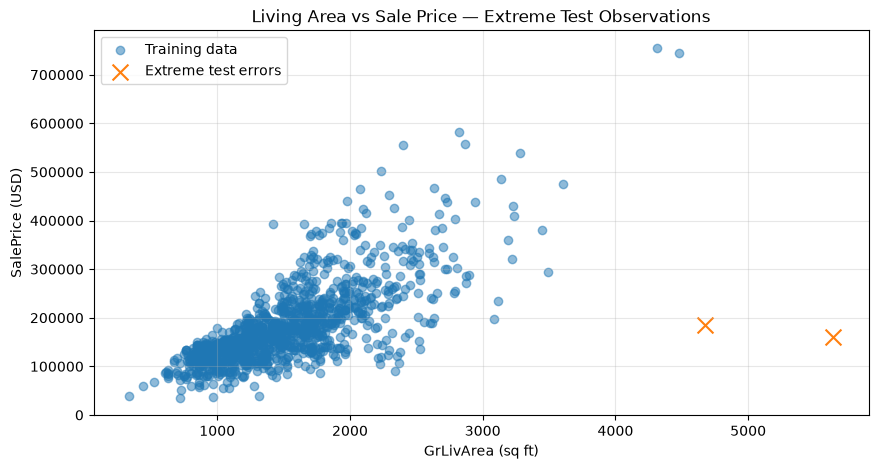

In [40]:
plt.figure(figsize=(10, 5))

plt.scatter(
    X_train["GrLivArea"],
    y_train,
    alpha=0.5,
    label="Training data",
)

plt.scatter(
    X_test.loc[worst_indices, "GrLivArea"],
    y_test.loc[worst_indices],
    marker="x",
    s=130,
    label="Extreme test errors",
)

plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.title("Living Area vs Sale Price — Extreme Test Observations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Error Analysis Summary

The selected model achieved a holdout RMSLE of **0.1618**,
compared with a cross-validation RMSLE of **0.1175**.

Further analysis revealed that two unusually large properties
accounted for **52.51% of the total squared logarithmic error**.

Both properties had very large living areas and high overall
quality ratings, but their actual sale prices were substantially
lower than predicted.

Excluding these two observations for diagnostic purposes reduced
RMSLE to **0.1119**, suggesting that the holdout performance is
strongly influenced by a small number of extreme cases.

The official holdout RMSLE remains **0.1618**. No observations
were removed from the final evaluation.


## Final Conclusions

### Model Selection

Several modeling strategies were evaluated, including a baseline
XGBoost model, hyperparameter optimization with Optuna, and
different feature selection approaches.

The jointly optimized feature selection approach achieved the
lowest cross-validation RMSLE (0.1169).

However, the tuned XGBoost model using all available features
achieved a comparable RMSLE (0.1175) with a simpler pipeline.

**Final decision:** Retain the tuned XGBoost model without
feature selection.

### Holdout Evaluation

The selected model was evaluated on the previously unseen
holdout dataset:

- Test RMSLE: 0.1618
- Test RMSE: $49,764.42
- Test MAE: $17,433.75

The holdout RMSLE was higher than the cross-validation RMSLE.

### Error Analysis

Two extreme observations accounted for 52.51% of the total
squared logarithmic error.

Both properties had exceptionally large living areas and
high overall quality ratings, but relatively low sale prices.

Excluding these observations for diagnostic purposes reduced
RMSLE to 0.1119. However, the official holdout RMSLE remains
0.1618.

### Limitations

The model performs substantially worse on certain unusual
properties. Its predictions may be less reliable when sale
prices are influenced by factors not adequately represented
in the available features.

Hyperparameters and modeling strategies were selected using
cross-validation on the training data. The holdout dataset
was reserved for final evaluation.

### Next Steps

- Serialize the fitted preprocessing and XGBoost pipeline.
- Validate predictions after loading the saved model.
- Prepare the model for serving through FastAPI.
- Containerize the application with Docker.
- Introduce automated testing and deployment workflows.
